# Day 20 – Hexagons | Tokyo Through Photographs

**Author** · María Victoria León Parra  
**Challenge** · Day 20 · Hexagons · #30DayMapChallenge 2026

Where do photographs concentrate across Tokyo, and which local groups does DBSCAN identify? The input is the [Tokyo sample](https://geographicdata.science/book/data/tokyo/tokyo_cleaning.html) of Flickr photographs attributed to Yahoo’s YFCC100M collection. This notebook adapts [Point Pattern Analysis](https://geographicdata.science/book/notebooks/08_point_pattern_analysis.html) by Serge J. Rey, Dani Arribas-Bel and Levi J. Wolf.

Audit the CSV, project the coordinates to local metres, explore the point pattern, compare DBSCAN parameters, aggregate photographs to a regular grid, and export reusable layers and a print map.

## 1. Audit the chapter CSV

The preparation notebook documents a random 10,000-row subset with seed 1234. The shared workflow checks the book repository snapshot’s SHA-256, coordinate validity, missing fields, exact rows and photo URLs. Shared coordinates are retained for distinct photographs. The file stores a user ID, longitude, latitude, reported capture timestamp, photo page URL and supplied Web Mercator x/y. The supplied x/y are checked against reprojected WGS 84 coordinates. Analysis uses Japan Plane Rectangular CS IX (EPSG:6677), in metres.

In [1]:
from IPython.display import display
from matplotlib import pyplot as plt
import make_map as workflow

points, audit = workflow.load_photographs()
display(audit)

{'source_rows': 10000,
 'invalid_coordinate_rows': 0,
 'exact_duplicate_rows_removed': 0,
 'duplicate_photo_urls_after_exact_deduplication': 0,
 'rows_with_previously_seen_coordinates': 2713,
 'unique_user_ids': 1825,
 'raw_nulls_by_field': {'user_id': 0,
  'longitude': 0,
  'latitude': 0,
  'date_taken': 0,
  'photo/video_page_url': 0,
  'x': 0,
  'y': 0},
 'unparsed_capture_dates': 0,
 'earliest_capture_timestamp': '1923-09-01 00:00:00',
 'latest_capture_timestamp': '2017-05-14 17:21:16',
 'capture_dates_outside_2004_through_2014': 85,
 'max_web_mercator_discrepancy_m': 9.723293137653312e-09}

## 2. Explore the point pattern

Use the scatter, mean center, Euclidean median and standard distance to describe the geometry. The sorted distance to the 100th sample (including each query point) shows how the neighbourhood scale varies from dense central locations to more dispersed points.

,mean_easting_m,mean_northing_m,median_easting_m,median_northing_m,standard_distance_m
0,-8694.0,-36405.0,-8153.0,-36132.0,7125.0


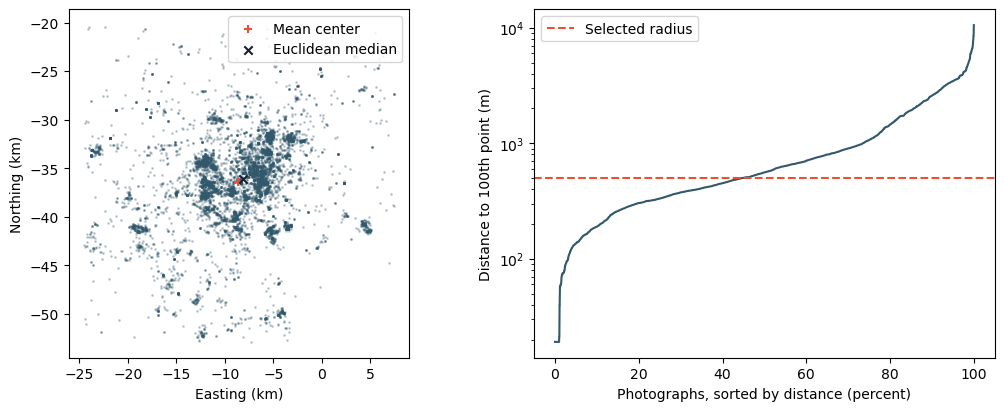

In [2]:
exploration, measures = workflow.explore(points)
display(measures.round())
display(exploration)
plt.close(exploration)

## 3. Compare DBSCAN settings

Epsilon is the radius within which photographs count as neighbours. Minimum samples is the number in that radius, including the point itself, needed for a point to be a core. Connected cores can span a larger distance than epsilon, and points within reach can join as border members. Noise is labelled −1. Zero is a valid cluster ID.

Choose 500 m and 100 photographs as in the chapter’s neighbourhood-scale example, using local metres here. At 350 m and 100 the main areas split into smaller groups. A larger radius or a lower core threshold connects concentrations that the 500 m / 100 run resolves separately. See the sensitivity table and cluster median locations below.

In [3]:
points, sensitivity, footprints = workflow.cluster_photographs(points)
display(sensitivity)
display(footprints.drop(columns="geometry").round(5))

,epsilon_m,min_samples,selected,clusters,clustered_photographs,noise_photographs,largest_cluster
0,350,100,False,16,4436,5564,742
1,500,100,True,12,5975,4025,1604
2,500,50,False,14,7463,2537,3506
3,650,100,False,10,7176,2824,5189


,cluster_id,photographs,core_photographs,median_longitude,median_latitude,rank
0,1,1604,1153,139.76258,35.67501,1
1,0,924,753,139.70121,35.66521,2
2,11,888,718,139.77201,35.71157,3
3,6,629,518,139.70079,35.68961,4
4,7,399,347,139.79650,35.71291,5
5,8,345,288,139.72992,35.66252,6
6,10,305,218,139.73352,35.63755,7
7,2,240,120,139.77513,35.62620,8
8,4,168,143,139.79436,35.63028,9
9,9,164,22,139.57129,35.70113,10


## 4. Count hexagons and export

Use a fixed flat-top lattice with 375 m sides, 750 m vertex-to-vertex, about 650 m across the flats and 0.365 km² per cell. The study window includes every retained point. Assign each photograph once, breaking shared-edge ties by the fixed lattice order. Unfilled cells record zero sample photographs. Positive cells use a logarithmic scale. For each of the four largest clusters, dissolve the hexagons where more than half of all photographs belong to that cluster. The outlines describe majority membership at the grid resolution.

The map uses a Natural Earth land crop and approximate place anchors checked against GO TOKYO’s map.

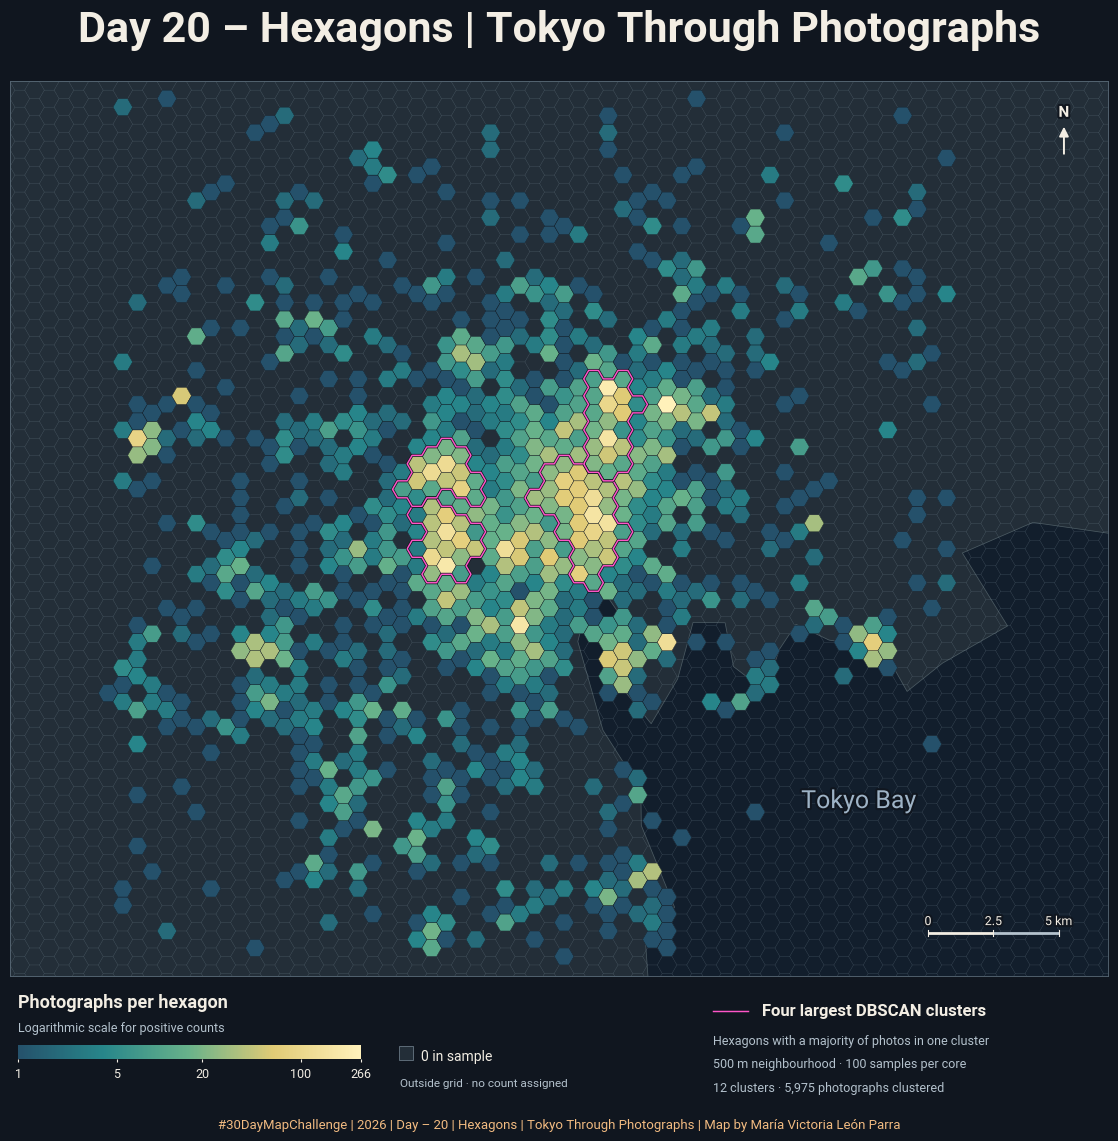

In [4]:
points, grid = workflow.count_hexagons(points)
land = workflow.load_land()

assert grid.photographs.sum() == len(points) == 10_000
assert points.cluster_role.eq("noise").equals(points.cluster_id.eq(-1))
assert footprints.photographs.sum() + points.cluster_id.eq(-1).sum() == len(points)

workflow.export(points, grid, footprints, land, sensitivity, measures, audit)
preview = workflow.draw_map(grid, workflow.cluster_hexagon_outlines(points, grid, footprints), footprints, land)
display(preview)
plt.close(preview)

## Findings, outputs and limitations

The 10,000 photographs occupy 977 of 4,104 cells. The highest counts occur near Asakusa (266), Ueno Park (214) and Shibuya Station (190). DBSCAN at 500 m and 100 samples finds 12 clusters with 5,975 photographs and leaves 4,025 as noise. The four largest clusters are near Ginza and the Tokyo Station area (1,604), Shibuya–Harajuku (924), Ueno and its surroundings (888) and Shinjuku (629). The Asakusa group has 399 photographs. These approximate place associations describe concentration patterns.

The CSV reports capture timestamps spanning 1923-09-01 through 2017-05-14, with 85 outside 2004–2014. The original corpus describes uploads from 2004 to early 2014. The reason for the discrepancy and the accuracy and time zone of the capture timestamps are unknown. All 10,000 records were retained, including 2,713 with previously seen coordinate pairs and distinct photo URLs.

The [PNG](outputs/day20-tokyo-through-photographs.png) and [vector PDF](outputs/day20-tokyo-through-photographs.pdf) share a 300 × 300 mm layout. The [GeoPackage](outputs/tokyo_photographs.gpkg) stores the photograph assignments, hexagon counts, buffered cluster footprints, hexagon outlines and land context. The output directory also holds [input audit](outputs/input_audit.json), [spatial summary](outputs/point_pattern_summary.csv), [parameter comparison](outputs/dbscan_sensitivity.csv), [cluster summaries](outputs/dbscan_clusters.csv) and [hexagon counts](outputs/hexagon_counts.csv).

The counts describe sampled photographs. Flickr participation, location tagging, Creative Commons selection, repeated contributions, position precision and the tutorial subset all shape the pattern. The counts cannot estimate visitors, visits or population. DBSCAN membership depends on its parameters and establishes neither statistical significance nor causes.

Photographs come from Flickr contributors and [Yahoo YFCC100M, Thomee et al.](https://arxiv.org/abs/1503.01817). The Tokyo sample and [tutorial](https://geographicdata.science/book/notebooks/08_point_pattern_analysis.html) are credited to Rey, Arribas-Bel and Wolf. Context uses [Natural Earth](https://www.naturalearthdata.com/downloads/10m-physical-vectors/10m-land/) and the [GO TOKYO visitor map](https://www.gotokyo.org/book/wp-content/uploads/2025/11/2511_mapoftokyo_EN_2_low.pdf).